# Homework Four (DSC 210, Spring 2026)

Name: Jacob Bauer

Date: 2026-03-31


The dataset `autos.csv` consists of data from 1985 Ward's Automotive Yearbook. Some more information about the dataset can be found [here](https://www.kaggle.com/datasets/toramky/automobile-dataset).

1. Read in the `autos.csv` dataset. What types of variables are there? How many observations are in the dataset?

In [4]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np

autos_df = pd.read_csv('car_data.csv')
autos_df.info()

# Vars: object, int, float
# Num observation: 11,914

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

2. Create a new dataframe containing only the numeric features from the `autos` dataset.

In [5]:
new_autos_df = autos_df.select_dtypes(include = ['number'])
new_autos_df.head()

,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
0,2011,335.0,6.0,2.0,26,19,3916,46135
1,2011,300.0,6.0,2.0,28,19,3916,40650
2,2011,300.0,6.0,2.0,28,20,3916,36350
3,2011,230.0,6.0,2.0,28,18,3916,29450
4,2011,230.0,6.0,2.0,28,18,3916,34500


3. Apply the IsolationForest method to detect outliers. Use a contamination level of 0.1. Then, create a new dataframe that contains only the non-outliers (as defined by the IsolationForest output). How many outliers were removed? How would changing the contamination level change the number of outliers removed?

In [11]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(n_estimators=100, contamination=0.1, n_jobs=-1, random_state=42, verbose=0)
iso_forest.fit(new_autos_df)
outlier_class = iso_forest.predict(new_autos_df)
autos_no_outliers = new_autos_df[outlier_class == 1].copy()
print(f"No outliers removed: {len(new_autos_df)}")
print(f"Outliers removed: {len(autos_no_outliers)}")

# If you increase contamination level the number of outliers increases
# If you decrease contamination level the number of outliers decreases

No outliers removed: 11914
Outliers removed: 10722


4. Create a correlation matrix and a pairplot (from seaborn). Are there any particularly strong correlations? Is this dataset a good candidate for dimension reduction? How do you know?

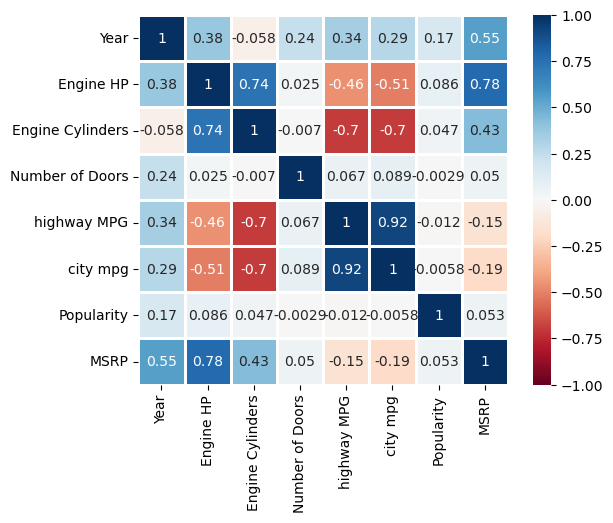

None


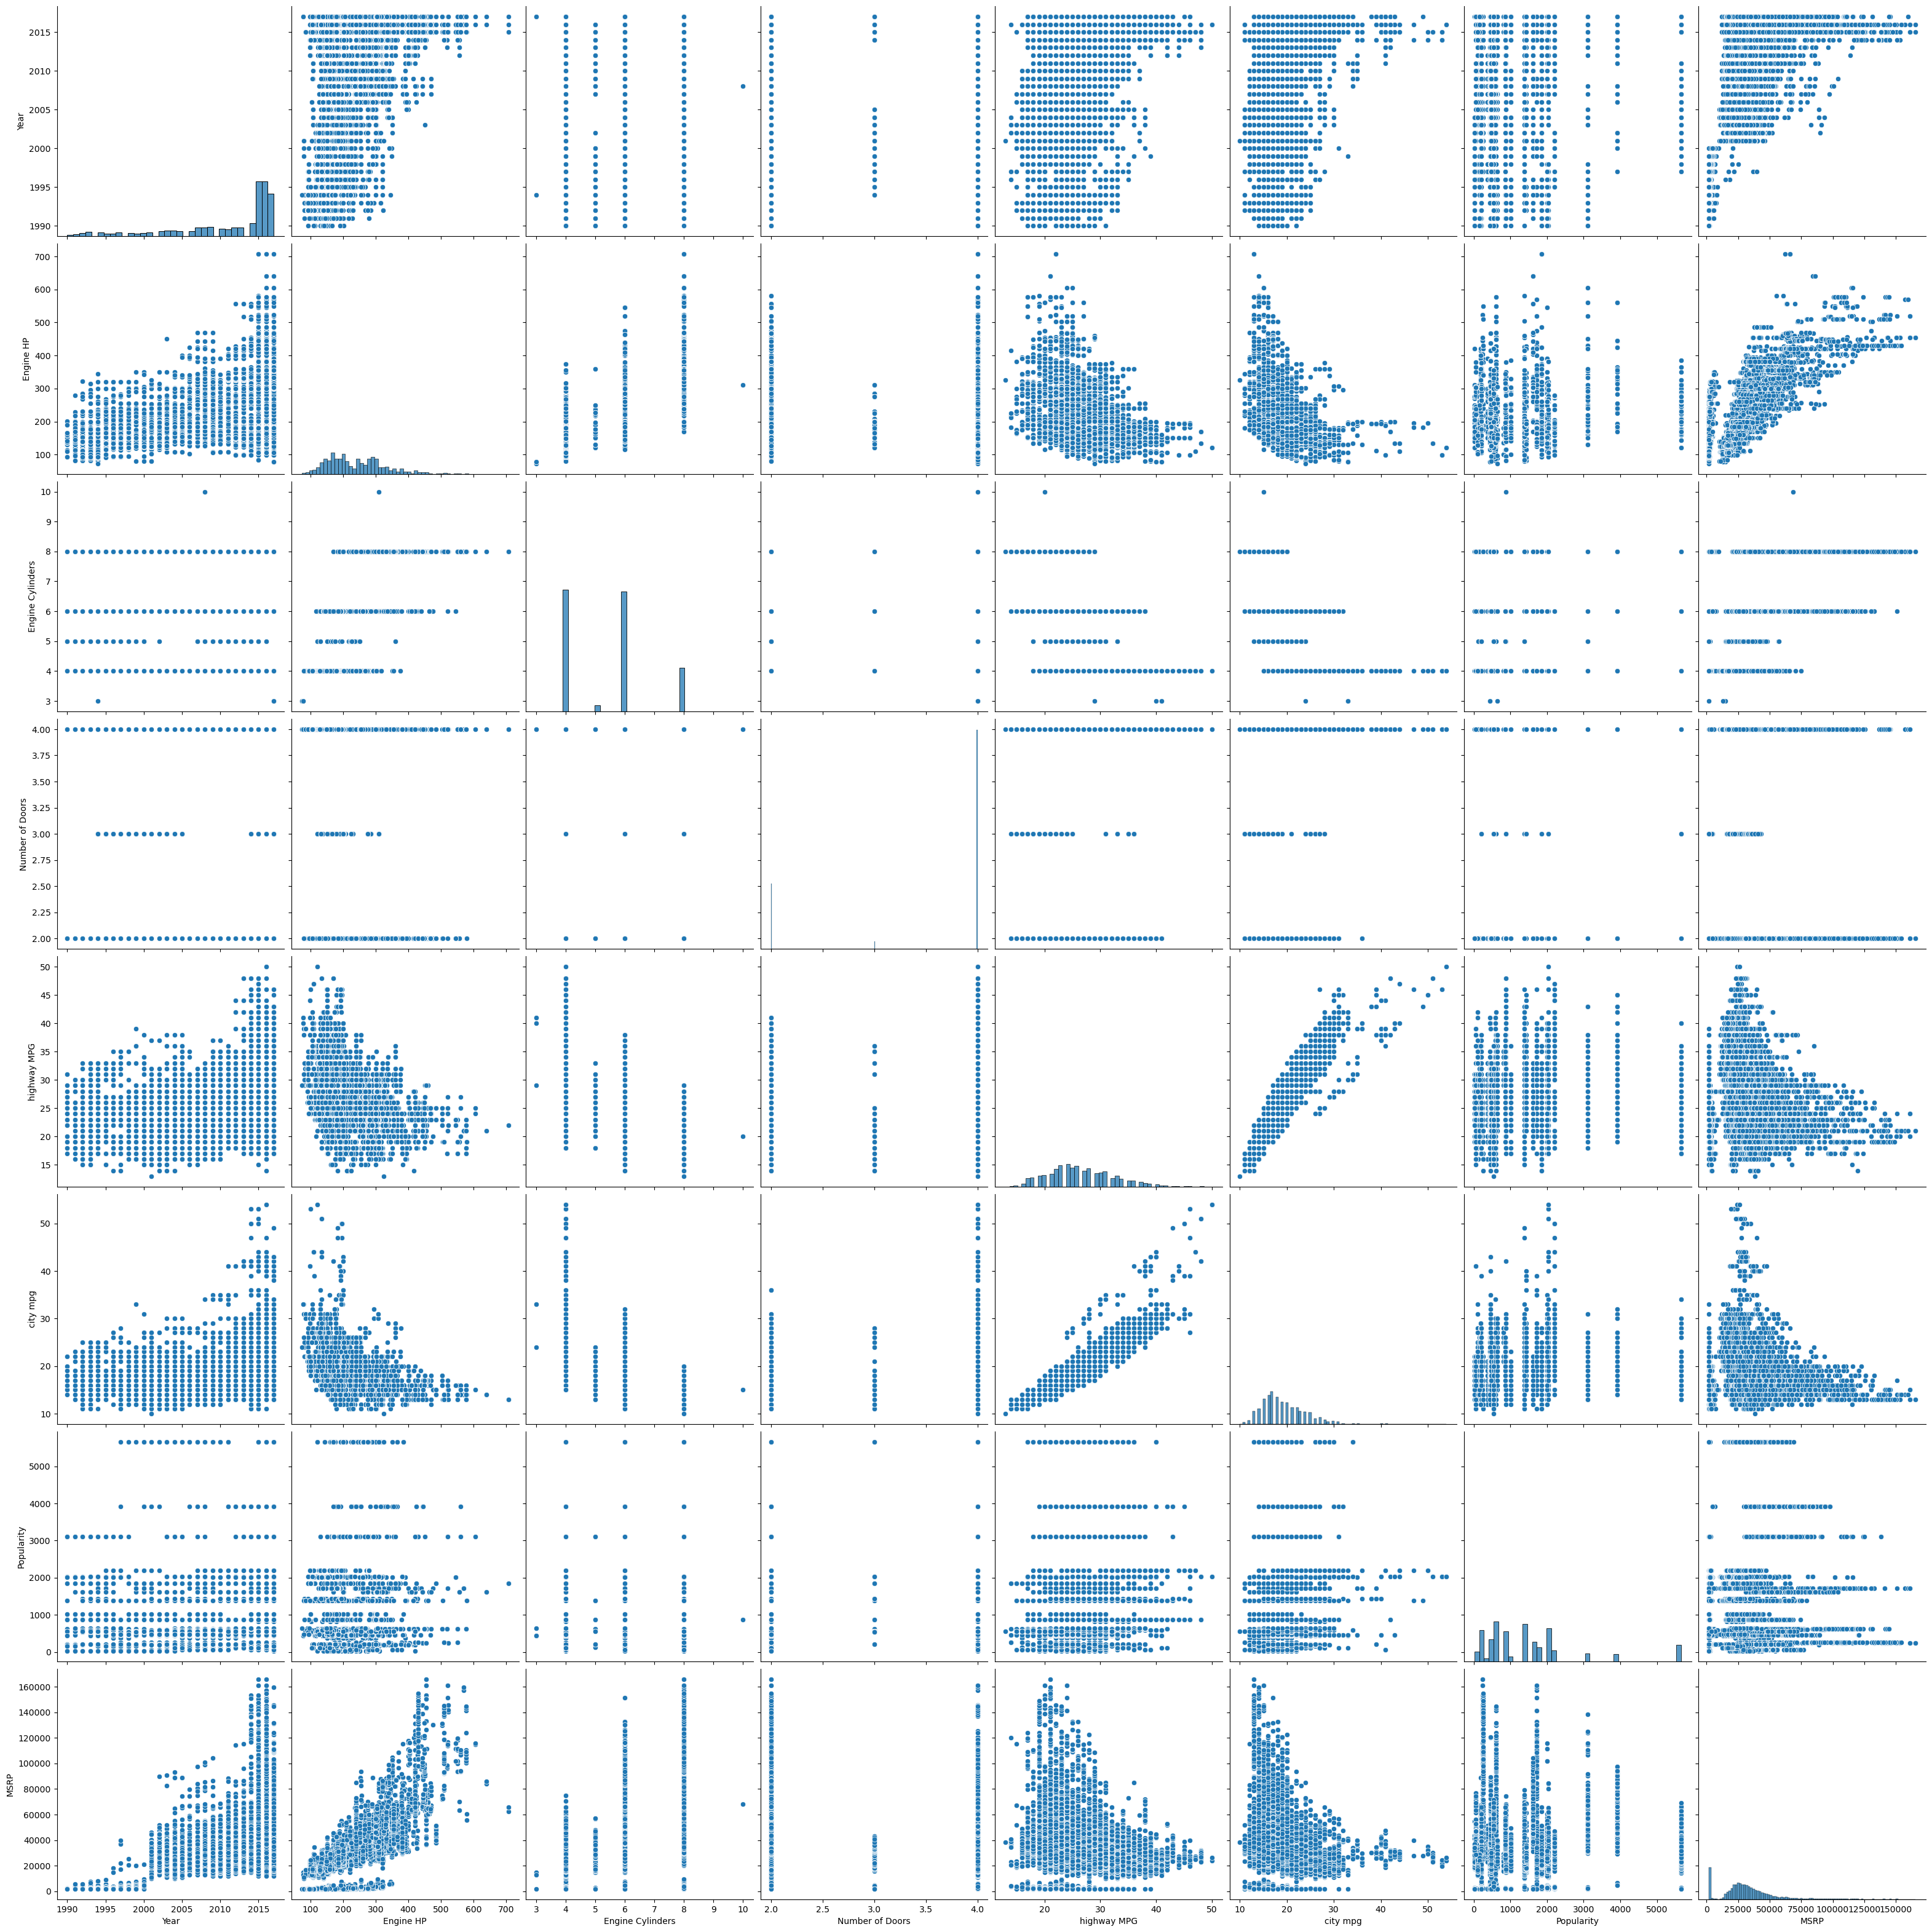

In [17]:
sns.heatmap(autos_no_outliers.corr(numeric_only=True), vmin=-1, vmax=1, square=True, lw=2, annot=True, cmap="RdBu")
print(plt.show())

sns.pairplot(autos_no_outliers, height=4)
plt.show()

# Strong corr: ENG cyl and ENG HP, HWY MPG and ENG cyl and CTY MPG and ENG cyl, HWY MPG and CTY MPG, ENG HP and MSRP
# This data set is a good candidate for dimension reduction based on how many variables are highly correlated

5. Apply PCA to reduce this dataset to 2 dimensions. Use this to answer the following:
  - Which variables loaded most onto PC1?
  - How much variation in the original data was explained using the first two principal components?
  - Create a plot of the first two principal components. Use color to highlight one of the variables that loaded heavily onto one of the principal component dimensions.

[[ 0.01990384  0.47177521  0.49633545 -0.01853134 -0.45166075 -0.46513993
   0.04049731  0.3291612 ]
 [ 0.64529294  0.29349932 -0.04676671  0.23056551  0.3291184   0.29487115
   0.14998156  0.47365094]]


[3.28254189 2.0051409 ]


[0.41027947 0.25061924]


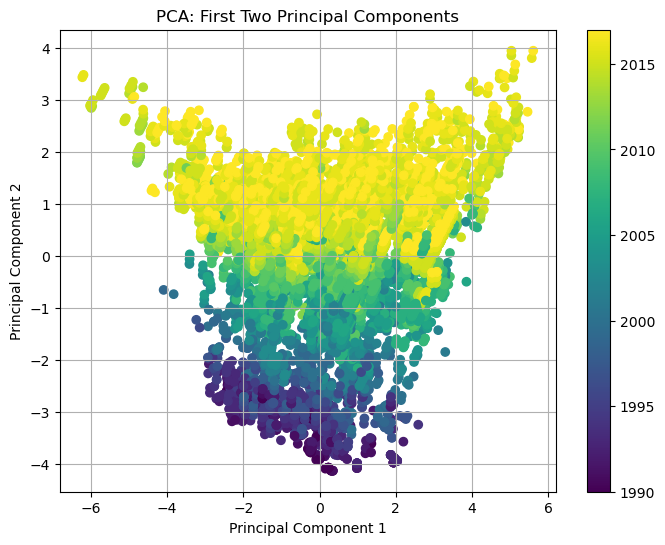

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
autos_no_outliers_imputed = imputer.fit_transform(autos_no_outliers)

scaler = StandardScaler()
autos_scaled = scaler.fit_transform(autos_no_outliers_imputed)
pca = PCA(n_components=2)
autos_pca = pca.fit_transform(autos_scaled)
print(pca.components_)
print("\n")
print(pca.explained_variance_)
print('\n')
print(pca.explained_variance_ratio_) # roughly 66% of the variance is explained by the first two pca

feature_to_highlight = 0 
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    autos_pca[:, 0],  
    autos_pca[:, 1],  
    c=autos_no_outliers_imputed[:, feature_to_highlight],  
    cmap='viridis')
plt.colorbar(scatter)
plt.title('PCA: First Two Principal Components')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()
